# 02 — Segmentação de clientes

**Objetivo:** agrupar clientes com padrões financeiros semelhantes e comparar a inadimplência entre os segmentos.

Base: *Default of Credit Card Clients* (UCI). Os clusters são construídos sem utilizar a variável-alvo.

In [19]:
from pathlib import Path
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.metrics import silhouette_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from ucimlrepo import fetch_ucirepo

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Funciona ao executar o notebook pela raiz ou pela pasta notebooks.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

( ROOT / "data" / "processed" ).mkdir(parents=True, exist_ok=True)
( ROOT / "reports" / "figures" ).mkdir(parents=True, exist_ok=True)
( ROOT / "models" ).mkdir(parents=True, exist_ok=True)

## 1. Dados e separação

Usamos a mesma regra de separação da EDA: perfis de entrada idênticos ficam no mesmo conjunto. A seleção do número de clusters será feita apenas com o treino.

In [20]:
colunas = {
    "X1": "LIMIT_BAL", "X2": "SEX", "X3": "EDUCATION",
    "X4": "MARRIAGE", "X5": "AGE", "X6": "PAY_0",
    "X7": "PAY_2", "X8": "PAY_3", "X9": "PAY_4",
    "X10": "PAY_5", "X11": "PAY_6", "X12": "BILL_AMT1",
    "X13": "BILL_AMT2", "X14": "BILL_AMT3", "X15": "BILL_AMT4",
    "X16": "BILL_AMT5", "X17": "BILL_AMT6", "X18": "PAY_AMT1",
    "X19": "PAY_AMT2", "X20": "PAY_AMT3", "X21": "PAY_AMT4",
    "X22": "PAY_AMT5", "X23": "PAY_AMT6"
}

dataset = fetch_ucirepo(id=350)
X = dataset.data.features.rename(columns=colunas).copy()
y = dataset.data.targets.iloc[:, 0].rename("inadimplente").astype(int)
X = X.drop(columns="ID", errors="ignore")

assert set(colunas.values()).issubset(X.columns)
assert len(X) == len(y)

grupos = pd.util.hash_pandas_object(X, index=False)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
idx_treino, idx_teste = next(splitter.split(X, y, groups=grupos))

X_train, X_test = X.iloc[idx_treino].copy(), X.iloc[idx_teste].copy()
y_train, y_test = y.iloc[idx_treino].copy(), y.iloc[idx_teste].copy()

assert set(grupos.iloc[idx_treino]).isdisjoint(set(grupos.iloc[idx_teste]))
print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Taxa de inadimplencia no treino:", f"{y_train.mean():.2%}")

Treino: (24000, 23) | Teste: (6000, 23)
Taxa de inadimplencia no treino: 22.12%


## 2. Variáveis de segmentação

Resumimos os seis meses em indicadores de limite, saldo, pagamentos e atrasos. Não incluímos sexo, idade, escolaridade, estado civil nem inadimplência no K-Means.

Para contar meses com atraso, usamos apenas status positivos. Códigos como `-2` não são tratados como atraso.

In [21]:
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
payment_cols = [f"PAY_AMT{i}" for i in range(1, 7)]


def criar_indicadores(base):
    atraso = base[pay_cols].clip(lower=0)
    indicadores = pd.DataFrame(index=base.index)
    indicadores["limite_credito"] = base["LIMIT_BAL"]
    indicadores["fatura_media"] = base[bill_cols].mean(axis=1)
    indicadores["pagamento_medio"] = base[payment_cols].mean(axis=1)
    indicadores["meses_em_atraso"] = (atraso > 0).sum(axis=1)
    indicadores["maior_atraso"] = atraso.max(axis=1)
    indicadores["atraso_medio"] = atraso.mean(axis=1)
    indicadores["uso_medio_limite"] = (
        indicadores["fatura_media"] / base["LIMIT_BAL"].replace(0, np.nan)
    )
    return indicadores.replace([np.inf, -np.inf], np.nan)

seg_train = criar_indicadores(X_train)
seg_test = criar_indicadores(X_test)

assert seg_train.notna().all().all(), "Existem valores invalidos nos indicadores de treino."
assert seg_test.notna().all().all(), "Existem valores invalidos nos indicadores de teste."

display(seg_train.describe().round(2))

,limite_credito,fatura_media,pagamento_medio,meses_em_atraso,maior_atraso,atraso_medio,uso_medio_limite
count,24000.00,24000.00,24000.00,24000.00,24000.00,24000.00,24000.00
mean,167807.90,45233.61,5307.78,0.83,0.68,0.28,0.37
std,129892.17,63545.28,10348.28,1.55,1.07,0.60,0.35
min,10000.00,-20913.33,0.00,0.00,0.00,0.00,-0.15
25%,50000.00,4841.25,1116.67,0.00,0.00,0.00,0.03
50%,140000.00,21229.25,2399.67,0.00,0.00,0.00,0.29
75%,240000.00,57508.96,5623.46,1.00,2.00,0.33,0.69
max,1000000.00,877313.83,627344.33,6.00,8.00,5.50,5.36


## 3. Preparação para o K-Means

Como os valores monetários têm escalas e assimetrias diferentes, aplicamos uma transformação `arcsinh` (adequada também para valores negativos) e depois padronizamos. O ajuste é feito exclusivamente no treino.

In [22]:
monetarias = ["limite_credito", "fatura_media", "pagamento_medio"]
comportamentais = ["meses_em_atraso", "maior_atraso", "atraso_medio", "uso_medio_limite"]


preprocessador = ColumnTransformer(
    transformers=[
        ("monetarias", Pipeline([
            ("log", FunctionTransformer(np.arcsinh, validate=False)),
            ("escala", StandardScaler())
        ]), monetarias),
        ("comportamentais", StandardScaler(), comportamentais)
    ]
)

Z_train = preprocessador.fit_transform(seg_train)
print("Dimensões da matriz de segmentação:", Z_train.shape)

Dimensões da matriz de segmentação: (24000, 7)


## 4. Escolha do número de clusters

Comparamos `k` de 2 a 7 pelo método do cotovelo (inércia) e pelo coeficiente *silhouette*. A decisão inicial usa o melhor *silhouette* no treino; depois verificamos se os segmentos têm tamanho e interpretação razoáveis.

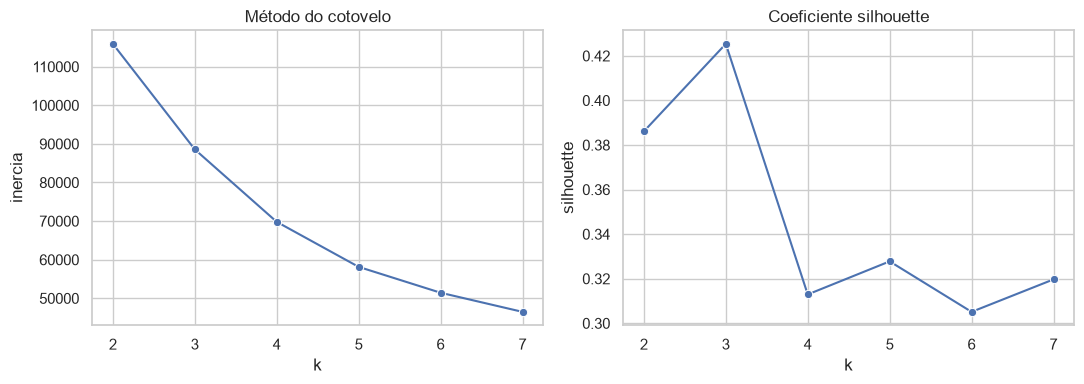

,k,inercia,silhouette
0,2,115905.531,0.386
1,3,88567.488,0.425
2,4,69800.248,0.313
3,5,58141.763,0.328
4,6,51442.822,0.305
5,7,46487.460,0.320


k sugerido pelo silhouette: 3


In [23]:
resultados_k = []
modelos_k = {}

for k in range(2, 8):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = modelo.fit_predict(Z_train)
    silhouette = silhouette_score(
        Z_train, labels,
        sample_size=min(2000, len(Z_train)),
        random_state=RANDOM_STATE
    )
    resultados_k.append({"k": k, "inercia": modelo.inertia_, "silhouette": silhouette})
    modelos_k[k] = modelo

metricas_k = pd.DataFrame(resultados_k)
k_escolhido = int(metricas_k.loc[metricas_k["silhouette"].idxmax(), "k"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.lineplot(data=metricas_k, x="k", y="inercia", marker="o", ax=axes[0])
axes[0].set_title("Método do cotovelo")
sns.lineplot(data=metricas_k, x="k", y="silhouette", marker="o", ax=axes[1])
axes[1].set_title("Coeficiente silhouette")
plt.tight_layout()
plt.savefig(ROOT / "reports" / "figures" / "02_escolha_k.png", dpi=140)
plt.show()

display(metricas_k.round(3))
print("k sugerido pelo silhouette:", k_escolhido)

## 5. Formação dos segmentos

Atribuímos um cluster para cada cliente do treino. Os clientes do teste recebem o segmento mais próximo usando o mesmo preprocessamento e os mesmos centroides.

In [24]:
modelo_final = modelos_k[k_escolhido]
segmentos_treino = pd.Series(
    modelo_final.labels_, index=seg_train.index, name="segmento"
)

Z_test = preprocessador.transform(seg_test)
segmentos_teste = pd.Series(
    modelo_final.predict(Z_test), index=seg_test.index, name="segmento"
)

print("Clientes por segmento (treino):")
display(segmentos_treino.value_counts().sort_index().rename("clientes").to_frame())

print("Clientes por segmento (teste):")
display(segmentos_teste.value_counts().sort_index().rename("clientes").to_frame())

Clientes por segmento (treino):


,clientes
segmento,
0,1335
1,17489
2,5176


Clientes por segmento (teste):


,clientes
segmento,
0,339
1,4374
2,1287


## 6. Perfil dos segmentos

Comparamos medianas por segmento para reduzir a influência de valores extremos. Os números dos clusters não indicam ordem de risco.

,clientes,limite_credito,fatura_media,pagamento_medio,meses_em_atraso,maior_atraso,atraso_medio,uso_medio_limite
segmento,,,,,,,,
0,1335,200000.0,0.00,0.0,1.0,1.0,0.17,0.00
1,17489,170000.0,21746.17,3165.5,0.0,0.0,0.00,0.21
2,5176,50000.0,29074.67,1650.0,3.0,2.0,1.00,0.68


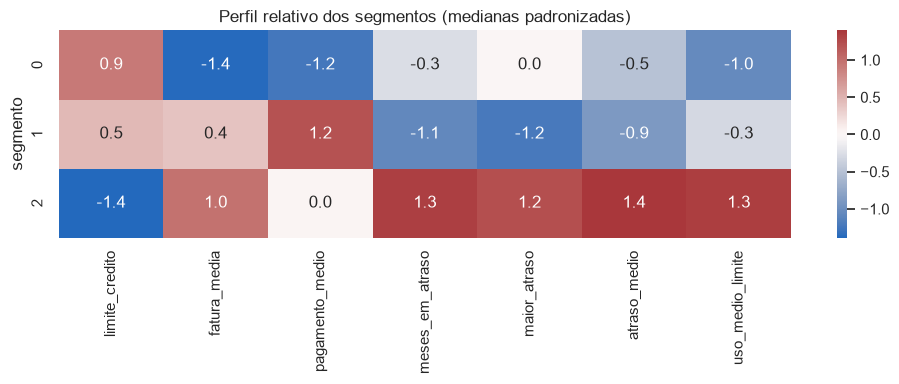

In [25]:
perfil = seg_train.join(segmentos_treino).groupby("segmento").median().round(2)
perfil.insert(0, "clientes", segmentos_treino.value_counts().sort_index())
display(perfil)

fig, ax = plt.subplots(figsize=(10, 4))
heat = perfil.drop(columns="clientes").copy()
heat = (heat - heat.mean()) / heat.std(ddof=0).replace(0, 1)
sns.heatmap(heat, cmap="vlag", center=0, annot=True, fmt=".1f", ax=ax)
ax.set_title("Perfil relativo dos segmentos (medianas padronizadas)")
plt.tight_layout()
plt.savefig(ROOT / "reports" / "figures" / "02_perfis_segmentos.png", dpi=140)
plt.show()

## 7. Inadimplência por segmento

A variável-alvo é usada **somente nesta etapa**, para comparar taxas observadas. Não foi utilizada para construir os grupos nem para escolher `k`. Mostramos treino e teste separadamente para evitar apresentar os números como se fossem validação de um modelo supervisionado.

Taxas no treino:


,segmento,clientes,inadimplentes,taxa_inadimplencia
0,0,1335,411,30.79
1,1,17489,2266,12.96
2,2,5176,2632,50.85


Taxas no teste:


,segmento,clientes,inadimplentes,taxa_inadimplencia
0,0,339,98,28.91
1,1,4374,558,12.76
2,2,1287,671,52.14


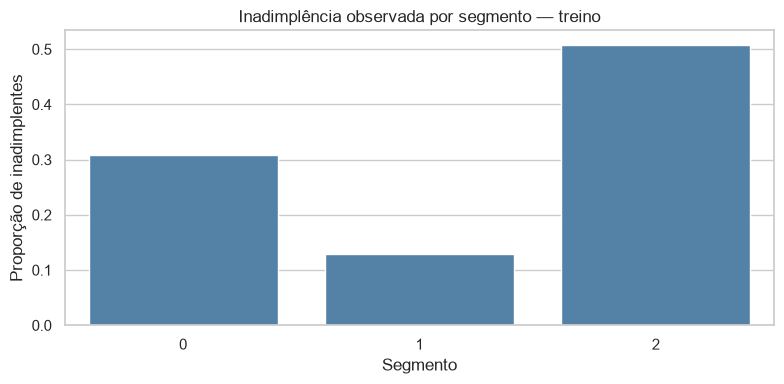

In [26]:
def resumo_risco(segmentos, alvo):
    tabela = pd.DataFrame({"segmento": segmentos, "inadimplente": alvo})
    return (
        tabela.groupby("segmento")["inadimplente"]
        .agg(clientes="size", inadimplentes="sum", taxa_inadimplencia="mean")
        .reset_index()
    )

risco_treino = resumo_risco(segmentos_treino, y_train)
risco_teste = resumo_risco(segmentos_teste, y_test)

print("Taxas no treino:")
display(risco_treino.assign(taxa_inadimplencia=lambda d: (100 * d.taxa_inadimplencia).round(2)))
print("Taxas no teste:")
display(risco_teste.assign(taxa_inadimplencia=lambda d: (100 * d.taxa_inadimplencia).round(2)))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=risco_treino, x="segmento", y="taxa_inadimplencia", color="steelblue", ax=ax)
ax.set_title("Inadimplência observada por segmento — treino")
ax.set_xlabel("Segmento")
ax.set_ylabel("Proporção de inadimplentes")
plt.tight_layout()
plt.savefig(ROOT / "reports" / "figures" / "02_risco_segmento.png", dpi=140)
plt.show()

## 8. Exportação

Salvamos os rótulos dos segmentos e o modelo para reutilização no dashboard e nas análises estatísticas. O campo `row_id` identifica a posição original na base carregada, não uma pessoa.

In [27]:
resultado_treino = seg_train.join(segmentos_treino).assign(inadimplente=y_train)
resultado_teste = seg_test.join(segmentos_teste).assign(inadimplente=y_test)

resultado_treino.rename_axis("row_id").to_csv(ROOT / "data" / "processed" / "segmentos_treino.csv")
resultado_teste.rename_axis("row_id").to_csv(ROOT / "data" / "processed" / "segmentos_teste.csv")

pipeline_segmentacao = Pipeline([
    ("preprocessamento", preprocessador),
    ("kmeans", modelo_final)
])
joblib.dump(pipeline_segmentacao, ROOT / "models" / "kmeans_segmentacao.joblib")

metadados = {
    "dataset": "UCI Default of Credit Card Clients (id=350)",
    "random_state": RANDOM_STATE,
    "n_clusters": k_escolhido,
    "colunas_segmentacao": list(seg_train.columns),
    "split": "primeiro fold StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)"
}
(ROOT / "models" / "segmentacao_metadata.json").write_text(
    json.dumps(metadados, indent=2, ensure_ascii=False), encoding="utf-8"
)

print("Arquivos salvos em data/processed/, reports/figures/ e models/.")

Arquivos salvos em data/processed/, reports/figures/ e models/.


## 9. Conclusão

O K-Means separou os clientes em **3 segmentos**. Entre os valores testados de `k` (2 a 7), essa escolha apresentou o maior silhouette na amostra de treino (**0,425**).

| Segmento | Clientes (treino) | Taxa no treino | Taxa no teste | Características principais |
| --- | ---: | ---: | ---: | --- |
| 0 | 1.335 | 30,79% | 28,91% | Fatura e pagamento medianos iguais a zero; requer análise adicional dos padrões de movimentação. |
| 1 | 17.489 | 12,96% | 12,76% | Menos meses em atraso e menor uso mediano do limite (0,21). |
| 2 | 5.176 | 50,85% | 52,14% | Mais meses em atraso (mediana de 3) e maior uso mediano do limite (0,68). |

O **segmento 2** concentrou o maior percentual de inadimplência, enquanto o **segmento 1** apresentou a menor taxa. No conjunto de teste, a diferença foi de **39,38 pontos percentuais** (52,14% versus 12,76%).

A distribuição é coerente com os indicadores usados no agrupamento, principalmente frequência de atrasos e uso do limite. Os resultados são descritivos: **não indicam causalidade** nem substituem a avaliação de um classificador de risco.

O segmento 0 merece investigação antes de receber um nome definitivo, porque as medianas de fatura e pagamento são zero, embora haja registros de atraso. A interpretação precisa considerar a distribuição completa das variáveis, não apenas as medianas.

**Limitações:** os clusters dependem das variáveis e escalas escolhidas; o silhouette foi estimado numa amostra de 2.000 observações por valor de `k`; e a base contém dados históricos de Taiwan, sem representar o cenário atual do crédito brasileiro.

**Próximo notebook:** `03_inadimplencia.ipynb` — comparação entre regressão logística e Random Forest, com validação cruzada, métricas e análise do limiar de decisão.
